# Part 2-1. 취소 예측의 비즈니스 효과 추정

Part 2의 취소 확률 모델을 **"누구에게 먼저 손을 쓸 것인가"** 라는 의사결정에 연결한다.

**시나리오:** 취소 확률이 임계값 이상인 예약에 선제 대응(재확인 연락, 보증금/결제 유도, 대체 판매 준비 등)을 한다.
- 대응 비용 `c`: 예약 1건당 비용 (데이터에 없으므로 **가정**)
- 대응 성공률 `s`: 취소했을 예약 중 대응으로 지켜내는 비율 (**가정**)
- 지켜낸 매출 = `s × adr × 숙박일수` (실제로 취소할 예약에 대해서만)
- 순효과 = Σ(지켜낸 매출) − Σ(대응 비용)

`c`, `s`는 실제 값을 알 수 없으므로 **민감도 분석**으로 "어떤 조건에서 이 모델이 돈이 되는가"를 보여준다.
평가는 Part 2와 같은 시간순 test 구간(예약일 2017-02-04 이후)만 사용한다.

In [1]:
import pandas as pd, numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('hotel_bookings.csv')
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-'
    + df['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
df['booking_date'] = df['arrival_date'] - pd.to_timedelta(df['lead_time'], unit='D')

# 시간순 분할 (Part 2와 동일)
df = df.sort_values('booking_date').reset_index(drop=True)
q70, q85 = df['booking_date'].quantile(0.70), df['booking_date'].quantile(0.85)
train = df[df['booking_date'] <= q70]
valid = df[(df['booking_date'] > q70) & (df['booking_date'] <= q85)]
test = df[df['booking_date'] > q85]
print(len(train), len(valid), len(test))

83580 18041 17769


In [2]:
# Part 2 전처리 재현: 누수 컬럼 제거, 결측 처리, agent 타깃 인코딩, 범주형 변환
DROP = ['reservation_status', 'reservation_status_date', 'assigned_room_type',
        'required_car_parking_spaces', 'arrival_date', 'booking_date', 'company',
        # 예약 이후 값이 쌓이는 변수(시점 누수 가능)와 시간 외삽 위험 변수 제외 (Part 2와 동일)
        'booking_changes', 'total_of_special_requests', 'days_in_waiting_list', 'arrival_date_year']

def prep(d):
    d = d.drop(columns=DROP).copy()
    d['children'] = d['children'].fillna(0)
    d['country'] = d['country'].fillna('Unknown')
    d['agent'] = d['agent'].fillna(0)
    return d

tr_p, va_p, te_p = prep(train), prep(valid), prep(test)

gm = tr_p['is_canceled'].mean()
agg = tr_p.groupby('agent')['is_canceled'].agg(['mean', 'count'])
smoothed = (agg['mean'] * agg['count'] + gm * 100) / (agg['count'] + 100)
for d in (tr_p, va_p, te_p):
    d['agent_te'] = d['agent'].map(smoothed).fillna(gm)
    d.drop(columns=['agent'], inplace=True)

cat_cols = ['hotel', 'meal', 'country', 'market_segment', 'distribution_channel',
            'reserved_room_type', 'deposit_type', 'customer_type', 'arrival_date_month']
top_countries = tr_p['country'].value_counts().head(20).index
for d in (tr_p, va_p, te_p):
    d['country'] = d['country'].where(d['country'].isin(top_countries), 'Other')
    for c in cat_cols:
        d[c] = d[c].astype('category')
# train 기준 카테고리로 통일 (valid/test에 없는 값이 있어도 안전)
for c in cat_cols:
    cats = tr_p[c].cat.categories
    for d in (va_p, te_p):
        d[c] = pd.Categorical(d[c].astype(object), categories=cats)

target = 'is_canceled'
X_tr, y_tr = tr_p.drop(columns=[target]), tr_p[target]
X_va, y_va = va_p.drop(columns=[target]), va_p[target]
X_te, y_te = te_p.drop(columns=[target]), te_p[target]

params = {'objective': 'binary', 'metric': 'auc', 'learning_rate': 0.05, 'num_leaves': 31,
          'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 5,
          'verbose': -1, 'seed': 42}
dtr = lgb.Dataset(X_tr, label=y_tr)
dva = lgb.Dataset(X_va, label=y_va, reference=dtr)
model = lgb.train(params, dtr, num_boost_round=1000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
p_te = model.predict(X_te)
print(f"Test AUC: {roc_auc_score(y_te, p_te):.4f}  (Part 2 재학습 LightGBM: 0.8270)")

Training until validation scores don't improve for 50 rounds


Early stopping, best iteration is:
[272]	valid_0's auc: 0.897325
Test AUC: 0.8271  (Part 2 재학습 LightGBM: 0.8270)


In [3]:
# 평가 테이블: 예약 1건 = 1행 (확률, 실제 취소, 예약 매출)
ev = test[['hotel', 'market_segment', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights']].copy()
ev['p'] = p_te
ev['y'] = y_te.values
ev['nights'] = ev['stays_in_weekend_nights'] + ev['stays_in_week_nights']
valid_price = (ev['adr'] > 0) & (ev['adr'] < 1000)
ev['rev'] = np.where(valid_price, ev['adr'] * ev['nights'], 0.0)   # 취소되면 잃는 예상 매출
ev['lost'] = ev['rev'] * ev['y']                                    # 실제로 잃은 매출

print("test 예약 수:", len(ev), "| 취소율:", ev['y'].mean().round(3))
print("예약 1건당 평균 예상 매출:", ev['rev'].mean().round(1))
print("취소로 잃은 총 매출:", f"{ev['lost'].sum():,.0f}", f"(전체 예상 매출의 {ev['lost'].sum()/ev['rev'].sum():.1%})")
print()
print(ev.groupby('hotel').agg(예약=('y', 'size'), 취소율=('y', 'mean'), 예상매출=('rev', 'sum'), 손실매출=('lost', 'sum')).round(3))

test 예약 수: 17769 | 취소율: 0.296
예약 1건당 평균 예상 매출: 446.3
취소로 잃은 총 매출: 2,854,567 (전체 예상 매출의 36.0%)

                 예약    취소율        예상매출        손실매출
hotel                                             
City Hotel    11509  0.313  4488100.71  1613925.47
Resort Hotel   6260  0.264  3442565.45  1240641.60


## 1. 임계값별 모델 성능과 "잃을 매출 포착률"

- precision: 대응 대상 중 실제 취소 비율
- recall: 전체 취소 중 대응 대상에 포함된 비율
- 매출 포착률: 취소로 잃은 매출 중 대응 대상에 포함된 비율

In [4]:
rows = []
for th in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    f = ev['p'] >= th
    rows.append({'임계값': th, '대상 예약수': f.sum(), '대상 비율': f.mean(),
                 'precision': ev.loc[f, 'y'].mean(), 'recall': ev.loc[f, 'y'].sum() / ev['y'].sum(),
                 '매출 포착률': ev.loc[f, 'lost'].sum() / ev['lost'].sum()})
thr_tbl = pd.DataFrame(rows).set_index('임계값').round(3)
print(thr_tbl.to_string())

     대상 예약수  대상 비율  precision  recall  매출 포착률
임계값                                          
0.3    7886  0.444      0.537   0.805   0.863
0.4    5693  0.320      0.578   0.626   0.692
0.5    3517  0.198      0.629   0.421   0.459
0.6    1459  0.082      0.723   0.201   0.210
0.7     472  0.027      0.907   0.081   0.076
0.8     331  0.019      0.982   0.062   0.043
0.9     310  0.017      0.997   0.059   0.035


## 2. 순효과 시뮬레이션과 민감도 분석

순효과(th) = Σ_{p ≥ th} [ s × 예상매출 × 실제취소 − c ]

비교 기준 3가지
1. **전수 대응:** 모든 예약에 대응 (모델 없이)
2. **무작위 대응:** 같은 건수를 무작위로 골라 대응 (모델의 순수 기여를 보기 위함)
3. **모델 기반 대응:** 확률 상위 예약에만 대응

In [5]:
def net_benefit(mask, s, c):
    return (s * ev.loc[mask, 'lost']).sum() - c * mask.sum()

def random_net_benefit(n, s, c):
    # 무작위로 n건을 고를 때의 기대 순효과 = n × (s × 평균 손실매출 − c)
    return n * (s * ev['lost'].mean() - c)

ths = np.round(np.arange(0.05, 0.96, 0.01), 2)
S_LIST = [0.1, 0.2, 0.3, 0.5]
C_LIST = [10, 25, 50, 100]

print(f"예약 1건당 평균 손실매출(취소로 잃는 금액): {ev['lost'].mean():.1f}\n")

best_rows = []
for s in S_LIST:
    for c in C_LIST:
        nb = np.array([net_benefit(ev['p'] >= th, s, c) for th in ths])
        k = nb.argmax()
        mask_best = ev['p'] >= ths[k]
        nb_all = net_benefit(pd.Series(True, index=ev.index), s, c)
        nb_rand = random_net_benefit(mask_best.sum(), s, c)
        best_rows.append({'성공률 s': s, '건당비용 c': c, '최적 임계값': ths[k], '대상 예약수': mask_best.sum(),
                          '모델 순효과': nb[k], '전수 대응': nb_all, '무작위(같은 건수)': nb_rand})
sens = pd.DataFrame(best_rows)
print(sens.round({'모델 순효과': 0, '전수 대응': 0, '무작위(같은 건수)': 0}).to_string(index=False))

예약 1건당 평균 손실매출(취소로 잃는 금액): 160.6



 성공률 s  건당비용 c  최적 임계값  대상 예약수    모델 순효과      전수 대응  무작위(같은 건수)
   0.1      10    0.19    9445  174323.0   107767.0     57283.0
   0.1      25    0.41    5481   55700.0  -158768.0    -48973.0
   0.1      50    0.69     514   -1637.0  -602993.0    -17443.0
   0.1     100    0.83     321  -20474.0 -1491443.0    -26943.0
   0.2      10    0.15   10237  445103.0   393223.0    226542.0
   0.2      25    0.23    8893  303660.0   126688.0     63405.0
   0.2      50    0.41    5481  111401.0  -317537.0    -97947.0
   0.2     100    0.69     514   -3273.0 -1205987.0    -34885.0
   0.3      10    0.11   11438  723027.0   678680.0    436870.0
   0.3      25    0.19    9445  570193.0   412145.0    219073.0
   0.3      50    0.28    8229  348088.0   -32080.0    -14857.0
   0.3     100    0.48    3936   47486.0  -920530.0   -203906.0
   0.5      10    0.07   12742 1286659.0  1249594.0    896073.0
   0.5      25    0.15   10237 1112757.0   983059.0    566355.0
   0.5      50    0.19    9445  871613.0

In [6]:
# 대표 시나리오 하나를 골라 임계값 곡선 그리기
S0, C0 = 0.3, 50
nb_curve = np.array([net_benefit(ev['p'] >= th, S0, C0) for th in ths])
cnt_curve = np.array([(ev['p'] >= th).sum() for th in ths])
nb_rand_curve = np.array([random_net_benefit(n, S0, C0) for n in cnt_curve])
nb_all = net_benefit(pd.Series(True, index=ev.index), S0, C0)

k = nb_curve.argmax()
print(f"대표 시나리오 s={S0}, c={C0}: 최적 임계값 {ths[k]}, 대상 {cnt_curve[k]:,}건 ({cnt_curve[k]/len(ev):.1%})")
print(f"  모델 기반 순효과 {nb_curve[k]:,.0f} | 전수 대응 {nb_all:,.0f} | 무작위 {nb_rand_curve[k]:,.0f}")
print(f"  지켜낸 매출 {S0 * ev.loc[ev['p'] >= ths[k], 'lost'].sum():,.0f} | 투입 비용 {C0 * cnt_curve[k]:,.0f}")

대표 시나리오 s=0.3, c=50: 최적 임계값 0.28, 대상 8,229건 (46.3%)
  모델 기반 순효과 348,088 | 전수 대응 -32,080 | 무작위 -14,857
  지켜낸 매출 759,538 | 투입 비용 411,450


## 3. 어디서 잃고 있나: 세그먼트별 손실 매출과 포착률

In [7]:
th = float(ths[k])
ev['flag'] = ev['p'] >= th
seg = ev.groupby('market_segment').agg(
    예약=('y', 'size'), 취소율=('y', 'mean'),
    손실매출=('lost', 'sum'), 대상예약=('flag', 'sum'))
seg['손실매출 비중'] = seg['손실매출'] / seg['손실매출'].sum()
seg['포착 손실매출'] = ev[ev['flag']].groupby('market_segment')['lost'].sum()
seg['포착 손실매출'] = seg['포착 손실매출'].fillna(0)
seg['포착률'] = seg['포착 손실매출'] / seg['손실매출']
print(f"(임계값 {th})")
print(seg.sort_values('손실매출', ascending=False).round(3).to_string())

print()
print(ev.groupby('hotel')[['lost', 'flag', 'y']].apply(lambda g: pd.Series({
    '손실매출': g['lost'].sum(), '포착률': g.loc[g['flag'], 'lost'].sum() / g['lost'].sum(),
    'precision': g.loc[g['flag'], 'y'].mean()})).round(3))

(임계값 0.28)
                   예약    취소율        손실매출  대상예약  손실매출 비중     포착 손실매출    포착률
market_segment                                                            
Online TA       11055  0.349  2278347.82  6901    0.798  2138272.80  0.939
Direct           2955  0.152   252056.34   281    0.088    95704.93  0.380
Offline TA/TO    1678  0.213   159051.36   436    0.056   144142.40  0.906
Groups            804  0.466   110360.44   419    0.039   105966.44  0.960
Corporate         999  0.168    48838.11   166    0.017    43522.91  0.891
Aviation          103  0.204     5834.00    22    0.002     4106.00  0.704
Complementary     175  0.160       79.00     4    0.000       79.00  1.000

                    손실매출    포착률  precision
hotel                                     
City Hotel    1613925.47  0.919      0.506
Resort Hotel  1240641.60  0.845      0.616


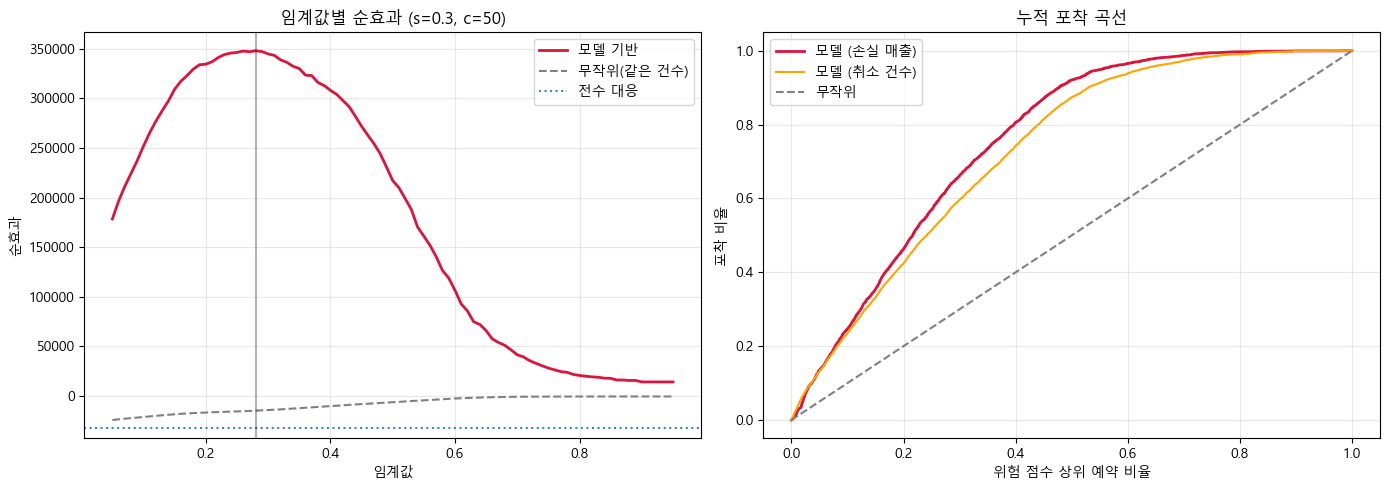

상위 10% 예약 → 취소 23.4%, 손실 매출 24.6% 포착
상위 20% 예약 → 취소 42.5%, 손실 매출 46.3% 포착
상위 30% 예약 → 취소 59.6%, 손실 매출 66.2% 포착


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) 임계값별 순효과: 모델 vs 무작위 vs 전수 대응
ax = axes[0]
ax.plot(ths, nb_curve, label='모델 기반', color='crimson', linewidth=2)
ax.plot(ths, nb_rand_curve, label='무작위(같은 건수)', color='gray', linestyle='--')
ax.axhline(nb_all, color='steelblue', linestyle=':', label='전수 대응')
ax.axvline(ths[k], color='black', alpha=0.3)
ax.set_xlabel('임계값'); ax.set_ylabel('순효과'); ax.set_title(f'임계값별 순효과 (s={S0}, c={C0})')
ax.legend(); ax.grid(alpha=0.3)

# (2) 누적 포착 곡선: 위험 점수 상위 x%가 전체 손실 매출의 몇 %를 포함하나
ax = axes[1]
order = ev.sort_values('p', ascending=False)
x = np.arange(1, len(order) + 1) / len(order)
ax.plot(x, order['lost'].cumsum() / order['lost'].sum(), label='모델 (손실 매출)', color='crimson', linewidth=2)
ax.plot(x, order['y'].cumsum() / order['y'].sum(), label='모델 (취소 건수)', color='orange')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='무작위')
ax.set_xlabel('위험 점수 상위 예약 비율'); ax.set_ylabel('포착 비율')
ax.set_title('누적 포착 곡선'); ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('business_impact.png', dpi=120, bbox_inches='tight')
plt.show()

for q in [0.1, 0.2, 0.3]:
    top = order.head(int(len(order) * q))
    print(f"상위 {q:.0%} 예약 → 취소 {top['y'].sum()/ev['y'].sum():.1%}, 손실 매출 {top['lost'].sum()/ev['lost'].sum():.1%} 포착")

In [9]:
thr_tbl.to_csv('cancel_threshold_table.csv', encoding='utf-8-sig')
sens.round(1).to_csv('cancel_sensitivity.csv', index=False, encoding='utf-8-sig')

## 4. 이상 집단(Non Refund) 의존성 점검

EDA에서 `deposit_type = Non Refund`는 취소율 99%에 포르투갈 고객이 99%를 차지하는 **이상 집단**으로 확인됐다. 이 집단의 "취소 손실"이 실제 손실인지 의문이므로, 위 순효과(+348K)가 이 집단에 얼마나 의존하는지 두 가지로 확인한다.

1. **평가에서만 제외:** 모델은 그대로 두고, Non Refund 예약을 뺀 test로 순효과를 다시 계산
2. **학습과 평가 모두 제외:** Non Refund를 뺀 데이터로 모델을 다시 학습하고 같은 방식으로 평가

예약 수가 줄면 절대 금액이 줄어드므로, **손실 매출 대비 순효과 비율**도 함께 본다. 임계값은 각 설정에서 같은 방식(대표 시나리오 최적값)으로 다시 찾는다.

In [10]:
nr = (test['deposit_type'] == 'Non Refund').values
print(f"test 중 Non Refund: {nr.sum():,}건 ({nr.mean():.1%}) | 취소율 {ev.loc[nr, 'y'].mean():.3f}")
print(f"  전체 취소 중 비중 {ev.loc[nr, 'y'].sum() / ev['y'].sum():.1%} | 전체 손실 매출 중 비중 {ev.loc[nr, 'lost'].sum() / ev['lost'].sum():.1%}")
print("  Non Refund 국가 상위:", test.loc[nr, 'country'].value_counts().head(3).to_dict())

def build_ev(test_df, p, y):
    e = test_df[['hotel', 'market_segment', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights']].copy()
    e['p'] = p; e['y'] = y.values if hasattr(y, 'values') else y
    e['nights'] = e['stays_in_weekend_nights'] + e['stays_in_week_nights']
    vp = (e['adr'] > 0) & (e['adr'] < 1000)
    e['rev'] = np.where(vp, e['adr'] * e['nights'], 0.0); e['lost'] = e['rev'] * e['y']
    return e

def best_effect(e, s, c):
    nbs = np.array([(s * e.loc[e['p'] >= th, 'lost']).sum() - c * (e['p'] >= th).sum() for th in ths])
    k = nbs.argmax(); n_t = int((e['p'] >= ths[k]).sum())
    nb_all = (s * e['lost']).sum() - c * len(e)
    nb_rand = n_t * (s * e['lost'].mean() - c)
    return {'th': ths[k], 'n_target': n_t, 'share': n_t / len(e), 'model': nbs[k], 'all': nb_all, 'random': nb_rand}

def sens_grid(e):
    rows = []
    for s in S_LIST:
        for c in C_LIST:
            r = best_effect(e, s, c); rows.append({'s': s, 'c': c, '최적 임계값': r['th'], '모델 순효과': r['model'], '전수 대응': r['all'], '무작위': r['random']})
    return pd.DataFrame(rows)

# 설정 1: 평가에서만 제외 (모델 그대로)
ev1 = ev[~nr].copy()
# 설정 2: 학습/평가 모두 제외 (재학습)
train2, valid2, test2 = (d[d['deposit_type'] != 'Non Refund'] for d in (train, valid, test))


test 중 Non Refund: 308건 (1.7%) | 취소율 0.997
  전체 취소 중 비중 5.8% | 전체 손실 매출 중 비중 3.4%
  Non Refund 국가 상위: {'PRT': 297, 'ESP': 9, 'DEU': 1}


In [11]:
def fit_predict_subset(tr_df, va_df, te_df):
    tr, va, te = prep(tr_df), prep(va_df), prep(te_df)
    gm_ = tr['is_canceled'].mean()
    agg_ = tr.groupby('agent')['is_canceled'].agg(['mean', 'count'])
    sm_ = (agg_['mean'] * agg_['count'] + gm_ * 100) / (agg_['count'] + 100)
    for d in (tr, va, te):
        d['agent_te'] = d['agent'].map(sm_).fillna(gm_); d.drop(columns=['agent'], inplace=True)
    top_ = tr['country'].value_counts().head(20).index
    for d in (tr, va, te):
        d['country'] = d['country'].where(d['country'].isin(top_), 'Other')
        for c in cat_cols: d[c] = d[c].astype('category')
    for c in cat_cols:
        cats_ = tr[c].cat.categories
        for d in (va, te): d[c] = pd.Categorical(d[c].astype(object), categories=cats_)
    Xs = [d.drop(columns=['is_canceled']) for d in (tr, va, te)]; ys = [d['is_canceled'] for d in (tr, va, te)]
    dtr_ = lgb.Dataset(Xs[0], label=ys[0]); dva_ = lgb.Dataset(Xs[1], label=ys[1], reference=dtr_)
    m_ = lgb.train(params, dtr_, num_boost_round=1000, valid_sets=[dva_], callbacks=[lgb.early_stopping(50, verbose=False)])
    return m_.predict(Xs[2]), ys[2]

p2, y2 = fit_predict_subset(train2, valid2, test2)
ev2 = build_ev(test2, p2, y2)

S0, C0 = 0.3, 50
rows = []
for name, e in [('원래 (전체)', ev), ('1) 평가에서만 Non Refund 제외', ev1), ('2) 학습·평가 모두 제외 (재학습)', ev2)]:
    r = best_effect(e, S0, C0)
    rows.append({'설정': name, 'test 예약수': len(e), '취소율': e['y'].mean(), 'AUC': roc_auc_score(e['y'], e['p']),
                 '손실 매출': e['lost'].sum(), '최적 임계값': r['th'], '대상 비율': r['share'],
                 '모델 순효과': r['model'], '전수 대응': r['all'], '무작위': r['random'],
                 '순효과/손실매출': r['model'] / e['lost'].sum()})
cmp_nr = pd.DataFrame(rows).set_index('설정')
pd.set_option('display.width', 250)
print(f"\n대표 시나리오 s={S0}, c={C0}")
print(cmp_nr.round(3).to_string())
cmp_nr.round(4).to_csv('cancel_nonrefund_check.csv', encoding='utf-8-sig')



대표 시나리오 s=0.3, c=50
                        test 예약수    취소율    AUC       손실 매출  최적 임계값  대상 비율      모델 순효과      전수 대응        무작위  순효과/손실매출
설정                                                                                                                   
원래 (전체)                    17769  0.296  0.827  2854567.07    0.28  0.463  348088.344 -32079.879 -14856.510     0.122
1) 평가에서만 Non Refund 제외     17461  0.283  0.816  2756700.89    0.28  0.454  334128.490 -46039.733 -20885.443     0.121
2) 학습·평가 모두 제외 (재학습)       17461  0.283  0.816  2756700.89    0.28  0.460  338096.030 -46039.733 -21157.025     0.123


In [12]:
for name, e in [('1) 평가에서만 제외', ev1), ('2) 학습·평가 모두 제외', ev2)]:
    print(f"\n=== {name}: 민감도 (최적 임계값 기준) ===")
    print(sens_grid(e).round({'모델 순효과': 0, '전수 대응': 0, '무작위': 0}).to_string(index=False))
    order_ = e.sort_values('p', ascending=False)
    print("상위 10/20/30% 포착(손실 매출):", [f"{order_.head(int(len(order_) * q))['lost'].sum() / e['lost'].sum():.1%}" for q in (0.1, 0.2, 0.3)])
    print("호텔별 손실 매출:", e.groupby('hotel')['lost'].sum().round(0).to_dict())



=== 1) 평가에서만 제외: 민감도 (최적 임계값 기준) ===


  s   c  최적 임계값    모델 순효과      전수 대응       무작위
0.1  10    0.19  167616.0   101060.0   52883.0
0.1  25    0.41   53614.0  -160855.0  -47655.0
0.1  50    0.69    3927.0  -597380.0   -7082.0
0.1 100    0.83     440.0 -1470430.0   -1179.0
0.2  10    0.15  428610.0   376730.0  214223.0
0.2  25    0.23  291787.0   114815.0   56451.0
0.2  50    0.41  107228.0  -321710.0  -95310.0
0.2 100    0.69    7854.0 -1194760.0  -14164.0
0.3  10    0.11  696748.0   652400.0  415853.0
0.3  25    0.19  548533.0   390485.0  204333.0
0.3  50    0.28  334128.0   -46040.0  -20885.0
0.3 100    0.48   48826.0  -919090.0 -191019.0
0.5  10    0.07 1240806.0  1203740.0  857185.0
0.5  25    0.15 1071524.0   941825.0  535558.0
0.5  50    0.19  838080.0   505300.0  264414.0
0.5 100    0.29  426400.0  -367750.0 -163351.0
상위 10/20/30% 포착(손실 매출): ['25.8%', '47.7%', '67.0%']
호텔별 손실 매출: {'City Hotel': 1534959.0, 'Resort Hotel': 1221742.0}

=== 2) 학습·평가 모두 제외: 민감도 (최적 임계값 기준) ===


  s   c  최적 임계값    모델 순효과      전수 대응       무작위
0.1  10    0.22  168341.0   101060.0   50527.0
0.1  25    0.41   52069.0  -160855.0  -46006.0
0.1  50    0.61    5370.0  -597380.0   -9511.0
0.1 100    0.72     376.0 -1470430.0   -1179.0
0.2  10    0.12  429300.0   376730.0  243199.0
0.2  25    0.22  293032.0   114815.0   57404.0
0.2  50    0.41  104138.0  -321710.0  -92012.0
0.2 100    0.61   10740.0 -1194760.0  -19022.0
0.3  10    0.12  700311.0   652400.0  421159.0
0.3  25    0.22  548674.0   390485.0  195231.0
0.3  50    0.28  338096.0   -46040.0  -21157.0
0.3 100    0.49   51290.0  -919090.0 -162753.0
0.5  10    0.10 1242645.0  1203740.0  827955.0
0.5  25    0.12 1073251.0   941825.0  607998.0
0.5  50    0.22  841706.0   505300.0  252636.0
0.5 100    0.29  431483.0  -367750.0 -166573.0
상위 10/20/30% 포착(손실 매출): ['27.0%', '48.3%', '66.3%']
호텔별 손실 매출: {'City Hotel': 1534959.0, 'Resort Hotel': 1221742.0}
